## Pearson & Spearman Correlation

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Generate linear study data and curved monotonic data
np.random.seed(42)

# Pair 1: linear relationship, hours vs score
hours = np.clip(np.random.normal(loc=5, scale=1.5, size=80), 1, 9)
score = 50 + 4 * hours + np.random.normal(loc=0, scale=4, size=80)

# Pair 2: monotonic but curved, effort vs growth (exponential shape)
effort = np.random.uniform(low=1, high=10, size=80)
growth = np.exp(effort / 3) + np.random.normal(loc=0, scale=1.5, size=80)

# Build DataFrame
df = pd.DataFrame({"hours": hours, "score": score, "effort": effort, "growth": growth})
print(df.head())
print(df.describe())

      hours      score    effort     growth
0  5.745071  72.101597  7.409613  11.917342
1  4.792604  70.598864  3.135242   1.227011
2  5.971533  79.797707  3.928597   2.631486
3  7.284545  77.065098  7.718423  14.121956
4  4.648770  65.361105  6.846696   8.702977
           hours      score     effort     growth
count  80.000000  80.000000  80.000000  80.000000
mean    4.814240  69.211506   5.946298   9.983179
std     1.436225   6.783547   2.576656   7.554331
min     1.070382  53.567267   1.139110  -1.485940
25%     4.020395  64.953119   3.909522   4.284390
50%     4.809566  69.567799   6.161343   7.694335
75%     5.762263  74.127419   8.209555  15.771304
max     7.778417  83.136885   9.910485  27.222910


In [3]:
# Test H0: correlation = 0 for both pairs
alpha = 0.05

# Linear pair: both should be strong and significant
r_p, p_p = stats.pearsonr(df["hours"], df["score"])
r_s, p_s = stats.spearmanr(df["hours"], df["score"])
print(f"Hours-Score: Pearson r={r_p:.3f} p={p_p:.4f} | Spearman rho={r_s:.3f} p={p_s:.4f}")

# Curved monotonic pair: Spearman should be stronger than Pearson
r_p2, p_p2 = stats.pearsonr(df["effort"], df["growth"])
r_s2, p_s2 = stats.spearmanr(df["effort"], df["growth"])
print(f"Effort-Growth: Pearson r={r_p2:.3f} p={p_p2:.4f} | Spearman rho={r_s2:.3f} p={p_s2:.4f}")

for name, p in [("Pearson linear", p_p), ("Spearman linear", p_s), ("Pearson curved", p_p2), ("Spearman curved", p_s2)]:
    print(f"{name}: {'significant' if p < alpha else 'not significant'}")

Hours-Score: Pearson r=0.841 p=0.0000 | Spearman rho=0.818 p=0.0000
Effort-Growth: Pearson r=0.913 p=0.0000 | Spearman rho=0.962 p=0.0000
Pearson linear: significant
Spearman linear: significant
Pearson curved: significant
Spearman curved: significant


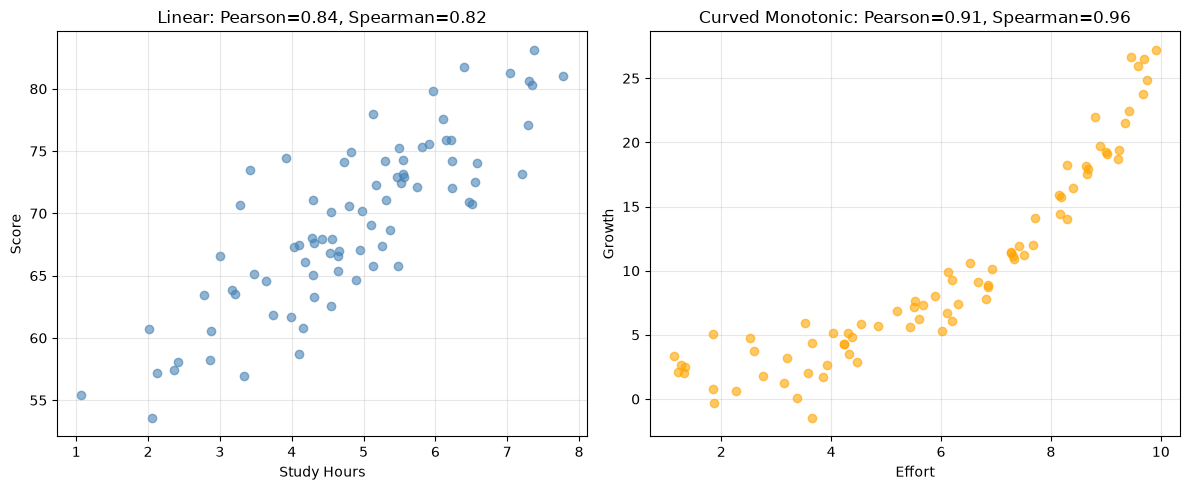

In [4]:
# Visualize linear vs curved relationship with scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left plot: linear data fits a straight line, both methods work
axes[0].scatter(df["hours"], df["score"], color="steelblue", alpha=0.6)
axes[0].set_title(f"Linear: Pearson={r_p:.2f}, Spearman={r_s:.2f}")
axes[0].set_xlabel("Study Hours")
axes[0].set_ylabel("Score")
axes[0].grid(alpha=0.3)

# Right plot: curved data, Spearman captures monotonic trend better
axes[1].scatter(df["effort"], df["growth"], color="orange", alpha=0.6)
axes[1].set_title(f"Curved Monotonic: Pearson={r_p2:.2f}, Spearman={r_s2:.2f}")
axes[1].set_xlabel("Effort")
axes[1].set_ylabel("Growth")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Experiment - one wild outlier breaks Pearson but not Spearman
hours_out = np.append(df["hours"].values, [9.0])
score_out = np.append(df["score"].values, [20.0])

r_p_out, _ = stats.pearsonr(hours_out, score_out)
r_s_out, _ = stats.spearmanr(hours_out, score_out)
print(f"Before outlier: Pearson={r_p:.3f}, Spearman={r_s:.3f}")
print(f"After one outlier: Pearson={r_p_out:.3f}, Spearman={r_s_out:.3f}")

# U-shaped relationship: neither method sees it, only scatter does
x_u = np.linspace(-3, 3, 100)
y_u = x_u**2 + np.random.normal(0, 0.5, 100)
r_u, _ = stats.pearsonr(x_u, y_u)
rho_u, _ = stats.spearmanr(x_u, y_u)
print(f"U-shape: Pearson={r_u:.3f}, Spearman={rho_u:.3f} (both near zero but relation exists)")

# Question: Why did Pearson drop much more than Spearman after the outlier?
# Question: Plot x_u vs y_u yourself. Why do both numbers lie here?

Before outlier: Pearson=0.841, Spearman=0.818
After one outlier: Pearson=0.426, Spearman=0.752
U-shape: Pearson=-0.011, Spearman=0.002 (both near zero but relation exists)
